<a href="https://colab.research.google.com/github/Avinash2567/MACHINE-LEARNING-ALGORITHM-IMPLEMENTATIONS/blob/main/07-principal-component-analysis/principal-component-analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [ ]:
import pandas as pd

data = pd.read_csv("/content/Iris.csv")

print(data.head())
print("Dataset shape:", data.shape)
print("Column names:", data.columns.tolist())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Dataset shape: (150, 6)
Column names: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


In [ ]:
print(data.isnull().sum())

print(data.isnull().any())

print("Duplicate rows:", data.duplicated().sum())

print(data.describe())

print(data.describe().T)

data = data.dropna()

print("Number of observations:", len(data))

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64
Id               False
SepalLengthCm    False
SepalWidthCm     False
PetalLengthCm    False
PetalWidthCm     False
Species          False
dtype: bool
Duplicate rows: 0
               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.445368       0.828066      0.433594       1.764420      0.763161
min      1.000000       4.300000      2.000000       1.000000      0.100000
25%     38.250000       5.100000      2.800000       1.600000      0.300000
50%     75.500000       5.800000      3.000000       4.350000      1.300000
75%    112.750000       6.400000      3.300000       5.100000      1.800000
max    150.000000       7.900000      4.400000       6.900000      2.500000
               count 

In [ ]:
X = data.select_dtypes(include=["number"]).copy()

id_columns = [
    col for col in X.columns
    if col.lower() in ["id", "unnamed: 0"]
]

X = X.drop(columns=id_columns)

print("Features used for PCA:")
print(X.columns.tolist())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("First five standardized rows:")
print(X_scaled[:5])

Features used for PCA:
['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
First five standardized rows:
[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_ * 100

print("Explained variance (%):", explained_variance)

print(
    "Total variance retained (%):",
    explained_variance.sum()
)

loadings = pd.DataFrame(
    pca.components_,
    index=["PC1", "PC2"],
    columns=X.columns
)

print("\nPrincipal component loadings:")
print(loadings.round(3))

Explained variance (%): [72.77045209 23.03052327]
Total variance retained (%): 95.80097536148199

Principal component loadings:
     SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
PC1          0.522        -0.263          0.581         0.566
PC2          0.372         0.926          0.021         0.065


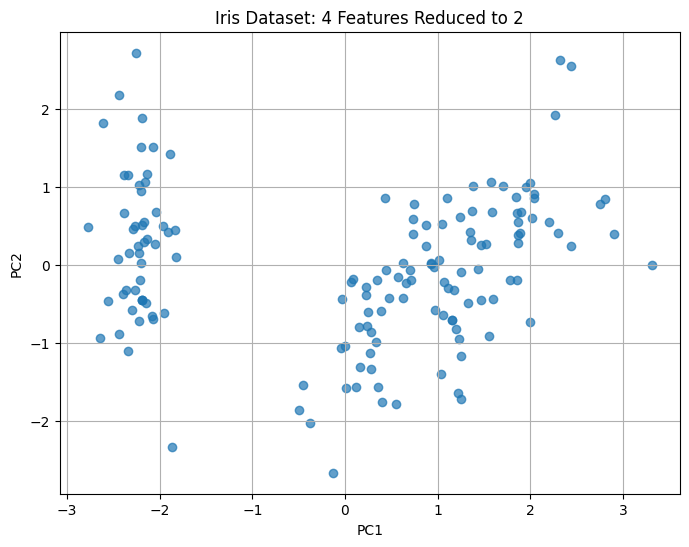

In [ ]:

plt.figure(figsize=(8, 6))

plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.7)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Iris Dataset: 4 Features Reduced to 2")
plt.grid(True)

plt.show()
